# PTB-XL records100: Transformer v2 learning curves

Train independent convolutional Transformer encoders on the existing **10%, 25%,
and 50% patient subsets** in `splits/`. Validate on fold 9 and evaluate once on
fold 10 after all training and threshold selection have finished. Inputs are
10-second, 100 Hz, 12-lead ECGs: `(1000, 12)`; outputs are five independent
diagnostic superclass probabilities in the order **NORM, MI, STTC, CD, HYP**.
`records100` refers to the sampling frequency, not a dataset of 100 recordings.

This notebook follows `transformer_v1.ipynb`. Changes are a convolutional temporal
embedding, sinusoidal positions, an automatic three-subset experiment, up to
30 epochs with early stopping, validation-selected F1 thresholds, and final
classwise AUROC, AUPRC (average precision), and F1 reports. Run every cell in order.
Dependencies are the project requirements; a Jupyter Python kernel is also needed.

## Expectations recorded before training

These are subjective ranges for this experiment, **not measured results or
confidence intervals**. They assume training from scratch and validation-selected
class thresholds. AUPRC below uses the average-precision definition.

| Training subset | Expected test macro AUROC | Expected test macro AUPRC | Expected test macro F1 |
|---|---|---|---|
| 10% | 0.84–0.89 | 0.65–0.75 | 0.60–0.70 |
| 25% | 0.88–0.92 | 0.73–0.82 | 0.68–0.77 |
| 50% | 0.90–0.94 | 0.77–0.86 | 0.72–0.81 |

At 50%, expected class F1 ranges are NORM 0.84–0.90, MI 0.72–0.82,
STTC 0.73–0.83, CD 0.74–0.84, HYP 0.45–0.65. The existing v1 run achieved
0.8350 **validation** macro AUROC on the 5% subset after five epochs; it did not
evaluate the test set. These experiments differ in embedding and training budget,
so this notebook is not a controlled ablation of the embedding alone.

## Architecture choice

A Transformer is a reasonable experiment, but a 1D ResNet or InceptionTime is an
important future baseline. The [PTB-XL benchmark](https://arxiv.org/abs/2004.13701)
found residual and inception CNNs particularly strong; an
[independent architecture comparison](https://proceedings.mlr.press/v149/nonaka21a.html)
also found ResNet-18 consistently strong. No CNN comparison is run here, so these
results cannot establish that a Transformer is the best model family.

The starting recommendation is an **encoder-only CNN–Transformer**. Three temporal
convolutions jointly embed all 12 leads into 50 overlapping tokens, with a
31-sample (310 ms) receptive field and a 20-sample (200 ms) step. Fixed sinusoidal
positions preserve temporal order without adding learned position parameters.
The encoder uses **128 features, 4 attention heads (32 features/head), 3 layers**,
512-wide feed-forward blocks, pre-layer normalization, and dropout 0.1. Mean
pooling and a five-logit head support multi-label BCE training. Lead identity is
encoded by the ordered input channels; no separate lead tokens, NLP embeddings,
spectrograms, or pretrained weights are used. This compact starting point needs
validation-based ablations to justify a different depth or number of heads.

The [PTB-XL source](https://physionet.org/content/ptb-xl/1.0.1/) describes the
100 Hz waveforms and patient-level fold protocol. We use the local files and
record their hashes, rather than downloading or regenerating splits.

In [1]:
import ast
import gc
import hashlib
import json
import math
import os
import random
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import wfdb
from IPython.display import display
from sklearn.metrics import (average_precision_score, f1_score,
                             precision_recall_curve, roc_auc_score)
from torch import nn
from torch.utils.data import DataLoader, Dataset

TRAIN_PERCENTS = (10, 25, 50)
CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SAMPLE_RATE, SIGNAL_LENGTH, N_LEADS = 100, 1000, 12
SEED = 42
BATCH_SIZE = 64
MAX_EPOCHS = 30
PATIENCE = 8
MIN_DELTA = 1e-4
LEARNING_RATE, MIN_LEARNING_RATE = 3e-4, 3e-5
WEIGHT_DECAY = 1e-2
MODEL_CONFIG = dict(d_model=128, n_heads=4, n_layers=3, dropout=0.1)

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'splits' / 'train_100.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter within the ecg_project repository.')
if os.environ.get('PTBXL_ROOT'):
    DATA_ROOT = Path(os.environ['PTBXL_ROOT']).expanduser().resolve()
else:
    base = PROJECT_ROOT / 'data' / 'ptbxl'
    candidates = ([base] if (base / 'records100').is_dir() else
                  sorted(p.parent for p in base.glob('*/records100') if p.is_dir()))
    if len(candidates) != 1:
        raise FileNotFoundError('Set PTBXL_ROOT to the folder containing records100/.')
    DATA_ROOT = candidates[0]
if not (DATA_ROOT / 'records100').is_dir():
    raise FileNotFoundError(f'Missing {DATA_ROOT / "records100"}')
if tuple(sorted(set(TRAIN_PERCENTS))) != TRAIN_PERCENTS or not set(TRAIN_PERCENTS) <= {10, 25, 50}:
    raise ValueError('Use increasing unique subsets from 10, 25, 50.')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_NAME = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + f'_seed{SEED}'
RUN_DIR = PROJECT_ROOT / 'artifacts' / 'transformer_v2' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + '\n')

print(f'PyTorch {torch.__version__}; device={DEVICE}; CPU threads={torch.get_num_threads()}')
print(f'Data: {DATA_ROOT}')
print(f'Artifacts: {RUN_DIR}')
print(f'Subsets={TRAIN_PERCENTS}; maximum {MAX_EPOCHS} epochs; patience={PATIENCE}')

PyTorch 2.14.1+cpu; device=cpu; CPU threads=4
Data: /home/madrdx/DL/project/ecg_project/data/ptbxl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
Artifacts: /home/madrdx/DL/project/ecg_project/artifacts/transformer_v2/20261027T020054956545Z_seed42
Subsets=(10, 25, 50); maximum 30 epochs; patience=8


## Audit the existing patient splits and labels

Training subsets must be nested and patient-disjoint from validation and test.
We verify record IDs, filenames, and folds against local metadata and audit
the five labels against its diagnostic superclass mapping. The provided CSV
labels remain the authoritative experiment targets and are used unchanged.
The initial audit found one difference: validation ECG 3799 has MI=0 in the CSV,
while local code-presence mapping gives MI=1 (IMI likelihood 15). Every other
requested training, validation, and test label agrees. The discrepancy is saved
in `label_audit.csv`; neither the CSVs nor the local metadata are rewritten.

In [2]:
frames = {f'train_{p}': pd.read_csv(PROJECT_ROOT / 'splits' / f'train_{p}.csv')
          for p in TRAIN_PERCENTS}
frames.update({name: pd.read_csv(PROJECT_ROOT / 'splits' / f'{name}.csv')
               for name in ('val', 'test')})
metadata = pd.read_csv(DATA_ROOT / 'ptbxl_database.csv').set_index('ecg_id')
scp = pd.read_csv(DATA_ROOT / 'scp_statements.csv', index_col=0)
mapping = scp.loc[scp['diagnostic'] == 1, 'diagnostic_class'].dropna().to_dict()
patient_sets = {name: set(frame.patient_id) for name, frame in frames.items()}
label_audit_rows = []
for name, frame in frames.items():
    assert frame.ecg_id.is_unique, f'Duplicate ECG IDs in {name}'
    assert frame.patient_id.notna().all(), f'Missing patient IDs in {name}'
    assert frame[CLASSES].isin([0, 1]).all().all(), f'Invalid binary labels in {name}'
    assert (frame[CLASSES].sum(axis=1) > 0).all(), f'Unlabeled records in {name}'
    assert frame.filename_lr.str.startswith('records100/').all()
    source = metadata.loc[frame.ecg_id]
    for column in ('patient_id', 'filename_lr', 'strat_fold'):
        assert np.array_equal(frame[column].to_numpy(), source[column].to_numpy()), (name, column)
    expected_labels = []
    for raw in source.scp_codes:
        superclasses = {mapping[c] for c in ast.literal_eval(raw) if c in mapping}
        expected_labels.append([int(c in superclasses) for c in CLASSES])
    expected_labels = np.asarray(expected_labels)
    actual_labels = frame[CLASSES].to_numpy()
    for row, column in np.argwhere(actual_labels != expected_labels):
        label_audit_rows.append({'split': name, 'ecg_id': int(frame.iloc[row].ecg_id),
                                 'class': CLASSES[column],
                                 'csv_label': int(actual_labels[row, column]),
                                 'metadata_label': int(expected_labels[row, column])})
    if name.startswith('train_'):
        assert frame.strat_fold.between(1, 8).all()
        for held_out in ('val', 'test'):
            assert patient_sets[name].isdisjoint(patient_sets[held_out]), (name, held_out)
    else:
        assert (frame.strat_fold == {'val': 9, 'test': 10}[name]).all()
assert patient_sets['val'].isdisjoint(patient_sets['test'])
for small, large in zip(TRAIN_PERCENTS[:-1], TRAIN_PERCENTS[1:]):
    assert patient_sets[f'train_{small}'] <= patient_sets[f'train_{large}']
    assert set(frames[f'train_{small}'].ecg_id) <= set(frames[f'train_{large}'].ecg_id)
    included = frames[f'train_{large}'].patient_id.isin(patient_sets[f'train_{small}'])
    assert set(frames[f'train_{large}'].loc[included, 'ecg_id']) == set(frames[f'train_{small}'].ecg_id)

split_summary = pd.DataFrame({
    name: {'recordings': len(frame), 'patients': frame.patient_id.nunique(),
           **frame[CLASSES].sum().to_dict()}
    for name, frame in frames.items()
}).T
display(split_summary)
split_summary.to_csv(RUN_DIR / 'split_summary.csv')
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
provenance = {
    'data_root': str(DATA_ROOT),
    'metadata_sha256': sha256(DATA_ROOT / 'ptbxl_database.csv'),
    'scp_sha256': sha256(DATA_ROOT / 'scp_statements.csv'),
    'split_sha256': {name: sha256(PROJECT_ROOT / 'splits' / f'{name}.csv') for name in frames},
}
save_json(RUN_DIR / 'provenance.json', provenance)
label_audit = pd.DataFrame(label_audit_rows, columns=['split', 'ecg_id', 'class', 'csv_label', 'metadata_label'])
label_audit.to_csv(RUN_DIR / 'label_audit.csv', index=False)
if len(label_audit):
    print('Label discrepancies found; retaining the frozen CSV labels:')
    display(label_audit)
print('Passed: metadata identity, official folds, patient separation, nested subsets.')

,recordings,patients,NORM,MI,STTC,CD,HYP
train_10,1687,1483,716,443,419,398,190
train_25,4252,3706,1862,1083,1017,1004,482
train_50,8521,7412,3757,2170,2061,2007,1027
val,2146,1917,955,540,528,495,268
test,2158,1877,963,550,521,496,262


Label discrepancies found; retaining the frozen CSV labels:


,split,ecg_id,class,csv_label,metadata_label
0,val,3799,MI,0,1


Passed: metadata identity, official folds, patient separation, nested subsets.


## Load 100 Hz signals once

The largest requested training subset plus validation and test is stored in a
run-specific NumPy memory-mapped file. Smaller training subsets index the same
raw recordings. Each WFDB signal is checked for shape, sampling rate, lead order,
units, and finite values. No normalization statistics are fit to held-out data.
The run-specific cache avoids accidentally reusing stale signals across runs.

In [3]:
all_records = (pd.concat([frames[f'train_{max(TRAIN_PERCENTS)}'], frames['val'], frames['test']],
                         ignore_index=True).sort_values('ecg_id').reset_index(drop=True))
assert all_records.ecg_id.is_unique
all_records.to_csv(RUN_DIR / 'signal_index.csv', index=False)
signal_path = RUN_DIR / 'signals.npy'
signals = np.lib.format.open_memmap(signal_path, mode='w+', dtype=np.float32,
                                    shape=(len(all_records), SIGNAL_LENGTH, N_LEADS))
LEADS = None
started = time.perf_counter()
for i, filename in enumerate(all_records.filename_lr):
    signal, fields = wfdb.rdsamp(str(DATA_ROOT / filename))
    if signal.shape != (SIGNAL_LENGTH, N_LEADS) or fields['fs'] != SAMPLE_RATE:
        raise ValueError(f'Unexpected signal shape/rate: {filename}')
    if not np.isfinite(signal).all():
        raise ValueError(f'Non-finite signal: {filename}')
    if LEADS is None:
        LEADS = fields['sig_name']
    if fields['sig_name'] != LEADS or any(unit != 'mV' for unit in fields['units']):
        raise ValueError(f'Unexpected lead order/units: {filename}')
    signals[i] = signal
    if (i + 1) % 2000 == 0:
        print(f'Loaded {i + 1:,}/{len(all_records):,} ECGs', flush=True)
signals.flush()
del signals
signals = np.load(signal_path, mmap_mode='r')
id_to_index = pd.Series(np.arange(len(all_records)), index=all_records.ecg_id)
indices = {name: id_to_index.loc[frame.ecg_id].to_numpy(dtype=np.int64)
           for name, frame in frames.items()}
labels = {name: frame[CLASSES].to_numpy(dtype=np.float32) for name, frame in frames.items()}
save_json(RUN_DIR / 'signal_manifest.json', {
    'shape': list(signals.shape), 'dtype': str(signals.dtype), 'leads': LEADS,
    'sample_rate': SAMPLE_RATE, 'units': 'mV', 'source': provenance,
})
print(f'Loaded {signals.shape}; {signals.nbytes / 1024**2:.1f} MiB on disk; '
      f'{time.perf_counter() - started:.1f}s')
print('Leads:', LEADS)

Loaded 2,000/12,825 ECGs
Loaded 4,000/12,825 ECGs
Loaded 6,000/12,825 ECGs
Loaded 8,000/12,825 ECGs
Loaded 10,000/12,825 ECGs
Loaded 12,000/12,825 ECGs
Loaded (12825, 1000, 12); 587.1 MiB on disk; 101.4s
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


In [4]:
class ECGDataset(Dataset):
    def __init__(self, raw_signals, record_indices, targets):
        self.raw_signals = raw_signals
        self.record_indices = record_indices
        self.targets = torch.from_numpy(targets)

    def __len__(self):
        return len(self.record_indices)

    def __getitem__(self, index):
        # Copy only one ECG from the read-only memmap into writable tensor storage.
        x = torch.from_numpy(np.array(self.raw_signals[self.record_indices[index]], copy=True))
        return x, self.targets[index]

def make_loader(name, training=False):
    return DataLoader(
        ECGDataset(signals, indices[name], labels[name]), batch_size=BATCH_SIZE,
        shuffle=training, generator=torch.Generator().manual_seed(SEED),
        num_workers=0, pin_memory=DEVICE.type == 'cuda',
    )

def training_statistics(record_indices):
    # Parallel Welford reduction: train-only per-lead population mean/std,
    # without allocating a normalized copy or a full float64 signal array.
    count = 0
    mean, m2 = np.zeros(N_LEADS), np.zeros(N_LEADS)
    for start in range(0, len(record_indices), 128):
        batch = np.asarray(signals[record_indices[start:start + 128]], dtype=np.float64)
        batch_count = batch.shape[0] * batch.shape[1]
        batch_mean = batch.mean(axis=(0, 1))
        batch_m2 = batch.var(axis=(0, 1)) * batch_count
        delta = batch_mean - mean
        new_count = count + batch_count
        m2 += batch_m2 + delta**2 * count * batch_count / new_count
        mean += delta * batch_count / new_count
        count = new_count
    return mean.astype(np.float32), np.maximum(np.sqrt(m2 / count), 1e-6).astype(np.float32)

print('Datasets use raw mV values; the model stores and applies its own train-only normalization.')

Datasets use raw mV values; the model stores and applies its own train-only normalization.


## Model: convolutional embedding → positional encoding → Transformer

Convolution lengths are `1000 → 500 → 250 → 50`; channels are
`12 → 32 → 64 → 128`. Batch normalization learns running statistics during
training only. Every encoder layer is constructed independently to avoid
identical initial weights across cloned layers. The same model and optimizer
configuration are used for all subsets; every run starts from a fresh seed-42
initialization. No transfer between the nested training subsets is performed.

In [5]:
class ECGTransformerV2(nn.Module):
    def __init__(self, lead_mean, lead_std, d_model=128, n_heads=4, n_layers=3, dropout=0.1):
        super().__init__()
        if d_model % n_heads or d_model % 2:
            raise ValueError('d_model must be even and divisible by n_heads.')
        self.register_buffer('lead_mean', torch.as_tensor(lead_mean).reshape(1, 1, N_LEADS))
        self.register_buffer('lead_std', torch.as_tensor(lead_std).reshape(1, 1, N_LEADS))
        self.stem = nn.Sequential(
            nn.Conv1d(N_LEADS, 32, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(32), nn.GELU(),
            nn.Conv1d(32, 64, kernel_size=5, stride=2, padding=2, bias=False),
            nn.BatchNorm1d(64), nn.GELU(),
            nn.Conv1d(64, d_model, kernel_size=5, stride=5, padding=2, bias=False),
            nn.BatchNorm1d(d_model), nn.GELU(),
        )
        self.n_tokens = 50
        positions = torch.arange(self.n_tokens, dtype=torch.float32).unsqueeze(1)
        frequency = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        encoding = torch.zeros(self.n_tokens, d_model)
        encoding[:, 0::2] = torch.sin(positions * frequency)
        encoding[:, 1::2] = torch.cos(positions * frequency)
        self.register_buffer('position_encoding', encoding.unsqueeze(0))
        self.embedding_norm = nn.LayerNorm(d_model)
        self.embedding_dropout = nn.Dropout(dropout)
        self.encoder_layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=d_model, nhead=n_heads, dim_feedforward=4 * d_model,
                dropout=dropout, activation='gelu', batch_first=True, norm_first=True,
            ) for _ in range(n_layers)
        ])
        self.output_norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, len(CLASSES))

    def forward(self, x):
        if x.ndim != 3 or tuple(x.shape[1:]) != (SIGNAL_LENGTH, N_LEADS):
            raise ValueError(f'Expected (batch, {SIGNAL_LENGTH}, {N_LEADS}), got {tuple(x.shape)}')
        x = ((x - self.lead_mean) / self.lead_std).transpose(1, 2)
        tokens = self.stem(x).transpose(1, 2)
        tokens = self.embedding_dropout(self.embedding_norm(tokens) + self.position_encoding)
        for layer in self.encoder_layers:
            tokens = layer(tokens)
        return self.classifier(self.output_norm(tokens).mean(dim=1))

probe = ECGTransformerV2(np.zeros(N_LEADS, np.float32), np.ones(N_LEADS, np.float32), **MODEL_CONFIG)
probe.eval()
with torch.inference_mode():
    probe_output = probe(torch.zeros(2, SIGNAL_LENGTH, N_LEADS))
assert probe_output.shape == (2, len(CLASSES)) and torch.isfinite(probe_output).all()
PARAMETER_COUNT = sum(p.numel() for p in probe.parameters() if p.requires_grad)
print(f'Trainable parameters: {PARAMETER_COUNT:,}; tokens: {probe.n_tokens}; output: {tuple(probe_output.shape)}')
del probe, probe_output

Trainable parameters: 650,309; tokens: 50; output: (2, 5)


## Metrics and threshold selection

AUROC and AUPRC use continuous probabilities, independently for each class.
**AUPRC is scikit-learn average precision (AP)**, a recall-weighted step integral,
not trapezoidal interpolation of the PR curve. Its no-skill reference is class
prevalence. Undefined AUROC/AP are recorded as NaN if a class lacks both outcomes.

F1 is reported twice: at the fixed probability threshold **0.5**, and at one
threshold per class chosen to maximize **validation F1** for the selected model.
Those thresholds are frozen before test inference. Equal validation-F1 maxima
use the threshold closest to 0.5. Macro metrics weight all five classes equally;
micro metrics flatten the labels. Validation-tuned F1 is a selection score;
the held-out test score is the final evaluation.

Prediction CSVs preserve the model probabilities at full precision. For exact
CSV round trips, reload probability columns as `np.float32` when reproducing threshold comparisons.

In [6]:
def classification_metrics(targets, probabilities, thresholds=None):
    thresholds = np.full(len(CLASSES), 0.5) if thresholds is None else np.asarray(thresholds)
    assert targets.shape == probabilities.shape and targets.shape[1] == len(CLASSES)
    assert thresholds.shape == (len(CLASSES),) and np.isfinite(thresholds).all()
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    rows = []
    tuned_predictions = probabilities >= thresholds.reshape(1, -1)
    fixed_predictions = probabilities >= 0.5
    for i, name in enumerate(CLASSES):
        valid = np.unique(targets[:, i]).size == 2
        rows.append({
            'class': name,
            'AUROC': roc_auc_score(targets[:, i], probabilities[:, i]) if valid else np.nan,
            'AUPRC': average_precision_score(targets[:, i], probabilities[:, i]) if valid else np.nan,
            'F1_at_0.5': f1_score(targets[:, i], fixed_predictions[:, i], zero_division=0),
            'F1_val_threshold': f1_score(targets[:, i], tuned_predictions[:, i], zero_division=0),
            'threshold': float(thresholds[i]),
            'positives': int(targets[:, i].sum()),
            'prevalence': float(targets[:, i].mean()),
        })
    return pd.DataFrame(rows).set_index('class')

def choose_validation_thresholds(targets, probabilities):
    thresholds = []
    for i in range(len(CLASSES)):
        if np.unique(targets[:, i]).size != 2:
            thresholds.append(0.5)
            continue
        precision, recall, candidates = precision_recall_curve(targets[:, i], probabilities[:, i])
        # The final (precision=1, recall=0) point has no corresponding threshold.
        scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
        best = np.flatnonzero(np.isclose(scores, scores.max(), rtol=0, atol=1e-12))
        selected = best[np.argmin(np.abs(candidates[best] - 0.5))]
        thresholds.append(float(candidates[selected]))
    return np.asarray(thresholds, dtype=np.float64)

def summarize_metrics(targets, probabilities, table, thresholds):
    return {
        'macro_AUROC': float(table.AUROC.mean()),
        'macro_AUPRC': float(table.AUPRC.mean()),
        'macro_F1_at_0.5': float(table['F1_at_0.5'].mean()),
        'macro_F1_val_threshold': float(table.F1_val_threshold.mean()),
        'micro_AUROC': float(roc_auc_score(targets.ravel(), probabilities.ravel())),
        'micro_AUPRC': float(average_precision_score(targets.ravel(), probabilities.ravel())),
        'micro_F1_at_0.5': float(f1_score(targets, probabilities >= 0.5, average='micro', zero_division=0)),
        'micro_F1_val_threshold': float(f1_score(targets, probabilities >= thresholds[None, :],
                                               average='micro', zero_division=0)),
    }

def predict(model, loader, criterion):
    model.eval()
    total_loss, target_batches, probability_batches = 0.0, [], []
    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite evaluation loss.')
            total_loss += loss.item() * len(y)
            target_batches.append(y.cpu().numpy())
            probability_batches.append(logits.sigmoid().cpu().numpy())
    return total_loss / len(loader.dataset), np.concatenate(target_batches), np.concatenate(probability_batches)

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x), y)
        if not torch.isfinite(loss):
            raise RuntimeError('Non-finite training loss.')
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0, error_if_nonfinite=True)
        optimizer.step()
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset)

def save_predictions(path, frame, targets, probabilities):
    result = frame[['ecg_id', 'patient_id']].reset_index(drop=True).copy()
    for i, name in enumerate(CLASSES):
        result[f'{name}_target'] = targets[:, i].astype(int)
        result[f'{name}_probability'] = probabilities[:, i].astype(np.float64)
    result.to_csv(path, index=False, float_format="%.17g")

## Train each subset and freeze its checkpoint and thresholds

Each model uses unweighted `BCEWithLogitsLoss`, AdamW, cosine learning-rate decay,
and gradient clipping at 1.0. The classifier bias starts at the training class
log-odds. Training stops after eight epochs without a validation macro AUROC
improvement of at least 0.0001, or at 30 epochs. The checkpoint with the highest
validation macro AUROC observed is saved, including smaller improvements; the
minimum delta affects the patience counter only. Architecture and training
settings are fixed in advance across subsets. Equal epoch limits mean that
larger subsets receive more optimizer steps; this is a training-data learning
curve, not a fixed-compute comparison.

No test metrics or test-based decisions are computed in this section. Checkpoints
include normalization buffers and sinusoidal positions. Each subset has its own
history, configuration, thresholds, and validation predictions. This single-seed
experiment measures neither seed variability nor statistical significance.

In [7]:
base_config = {
    'train_percents': list(TRAIN_PERCENTS), 'seed': SEED, 'batch_size': BATCH_SIZE,
    'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'min_delta': MIN_DELTA,
    'learning_rate': LEARNING_RATE, 'min_learning_rate': MIN_LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY, 'loss': 'unweighted BCEWithLogitsLoss',
    'model': MODEL_CONFIG, 'parameters': PARAMETER_COUNT, 'classes': CLASSES,
    'leads': LEADS, 'sample_rate': SAMPLE_RATE, 'signal_shape': [SIGNAL_LENGTH, N_LEADS],
    'device': str(DEVICE), 'torch_version': str(torch.__version__),
    'numpy_version': np.__version__, 'pandas_version': pd.__version__,
    'selection_metric': 'validation macro AUROC',
    'f1_threshold_selection': 'per-class maximum validation F1; ties closest to 0.5',
    'auprc_definition': 'sklearn average_precision_score', 'provenance': provenance,
}
save_json(RUN_DIR / 'config.json', base_config)
val_loader = make_loader('val')
training_runs = {}

def fit_subset(percent):
    seed_everything(SEED)
    name = f'train_{percent}'
    subset_dir = RUN_DIR / name
    subset_dir.mkdir(exist_ok=False)
    mean, std = training_statistics(indices[name])
    pd.DataFrame({'lead': LEADS, 'mean': mean, 'std': std}).to_csv(subset_dir / 'normalization.csv', index=False)
    config = {**base_config, 'train_percent': percent,
              'training_recordings': len(frames[name]),
              'training_patients': int(frames[name].patient_id.nunique())}
    save_json(subset_dir / 'config.json', config)
    model = ECGTransformerV2(mean, std, **MODEL_CONFIG).to(DEVICE)
    prevalence = torch.as_tensor(labels[name].mean(axis=0), device=DEVICE).clamp(1e-4, 1 - 1e-4)
    with torch.no_grad():
        model.classifier.bias.copy_(torch.logit(prevalence))
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS,
                                                          eta_min=MIN_LEARNING_RATE)
    train_loader = make_loader(name, training=True)
    history, best_auc, patience_reference, stale = [], -np.inf, -np.inf, 0
    best_epoch = None
    print(f'\nTraining {percent}%: {len(train_loader.dataset):,} ECGs', flush=True)
    for epoch in range(1, MAX_EPOCHS + 1):
        started = time.perf_counter()
        lr = optimizer.param_groups[0]['lr']
        train_loss = train_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_targets, val_probabilities = predict(model, val_loader, criterion)
        val_metrics = classification_metrics(val_targets, val_probabilities)
        score = float(val_metrics.AUROC.mean())
        if not np.isfinite(score):
            raise RuntimeError('Validation macro AUROC is undefined.')
        if score > best_auc:
            best_auc, best_epoch = score, epoch
            state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({'model_state_dict': state, 'config': config, 'epoch': epoch,
                        'val_macro_AUROC': best_auc}, subset_dir / 'best_model.pt')
            del state
        if score > patience_reference + MIN_DELTA:
            patience_reference, stale = score, 0
        else:
            stale += 1
        scheduler.step()
        row = {'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
               'val_macro_AUROC': score, 'val_macro_AUPRC': float(val_metrics.AUPRC.mean()),
               'val_macro_F1_at_0.5': float(val_metrics['F1_at_0.5'].mean()),
               'learning_rate': lr, 'seconds': time.perf_counter() - started}
        history.append(row)
        pd.DataFrame(history).to_csv(subset_dir / 'history.csv', index=False)
        print(f'{percent:2d}% epoch {epoch:02d}/{MAX_EPOCHS}: '
              f'train={train_loss:.4f} val={val_loss:.4f} '
              f'val AUROC={score:.4f} AP={row["val_macro_AUPRC"]:.4f} '
              f'({row["seconds"]:.1f}s)', flush=True)
        if stale >= PATIENCE:
            print(f'Early stopping: {PATIENCE} epochs without a material AUROC improvement.', flush=True)
            break
    checkpoint = torch.load(subset_dir / 'best_model.pt', map_location='cpu', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    val_loss, val_targets, val_probabilities = predict(model, val_loader, criterion)
    thresholds = choose_validation_thresholds(val_targets, val_probabilities)
    val_metrics = classification_metrics(val_targets, val_probabilities, thresholds)
    assert np.isclose(val_metrics.AUROC.mean(), best_auc), 'Restored checkpoint score mismatch'
    val_metrics.to_csv(subset_dir / 'validation_metrics.csv')
    save_predictions(subset_dir / 'validation_predictions.csv', frames['val'], val_targets, val_probabilities)
    save_json(subset_dir / 'thresholds.json', dict(zip(CLASSES, thresholds.tolist())))
    checkpoint['thresholds'] = thresholds.tolist()
    torch.save(checkpoint, subset_dir / 'best_model.pt')
    summary = {
        'train_percent': percent, 'train_recordings': len(frames[name]),
        'best_epoch': best_epoch, 'epochs_run': len(history),
        'training_seconds': float(sum(row['seconds'] for row in history)),
        'validation_loss': val_loss,
        **{f'val_{key}': value for key, value in summarize_metrics(
            val_targets, val_probabilities, val_metrics, thresholds).items()},
    }
    save_json(subset_dir / 'training_summary.json', summary)
    print(f'Frozen {percent}% checkpoint: epoch {best_epoch}, val AUROC={best_auc:.4f}', flush=True)
    print('Validation-selected thresholds:', dict(zip(CLASSES, thresholds.round(4))))
    del model, optimizer, scheduler, checkpoint
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return summary

In [8]:
for percent in TRAIN_PERCENTS:
    training_runs[percent] = fit_subset(percent)
    pd.DataFrame(training_runs.values()).to_csv(RUN_DIR / 'training_summary.csv', index=False)
training_summary = pd.DataFrame(training_runs.values()).set_index('train_percent')
display(training_summary[['train_recordings', 'best_epoch', 'epochs_run',
                          'val_macro_AUROC', 'val_macro_AUPRC',
                          'val_macro_F1_at_0.5', 'val_macro_F1_val_threshold']].round(4))
print('All checkpoints and F1 thresholds frozen. Test evaluation starts in the next section.')


Training 10%: 1,687 ECGs
10% epoch 01/30: train=0.4896 val=0.4415 val AUROC=0.8020 AP=0.5394 (8.3s)
10% epoch 02/30: train=0.4120 val=0.4012 val AUROC=0.8364 AP=0.6101 (7.6s)
10% epoch 03/30: train=0.3801 val=0.3866 val AUROC=0.8510 AP=0.6458 (7.1s)
10% epoch 04/30: train=0.3518 val=0.3789 val AUROC=0.8568 AP=0.6675 (7.3s)
10% epoch 05/30: train=0.3339 val=0.3698 val AUROC=0.8663 AP=0.6838 (7.7s)
10% epoch 06/30: train=0.3050 val=0.3654 val AUROC=0.8687 AP=0.6912 (7.4s)
10% epoch 07/30: train=0.2851 val=0.3641 val AUROC=0.8721 AP=0.7017 (7.4s)
10% epoch 08/30: train=0.2671 val=0.3722 val AUROC=0.8724 AP=0.7003 (7.6s)
10% epoch 09/30: train=0.2502 val=0.3787 val AUROC=0.8720 AP=0.7033 (7.8s)
10% epoch 10/30: train=0.2290 val=0.4176 val AUROC=0.8692 AP=0.7075 (7.5s)
10% epoch 11/30: train=0.2079 val=0.3999 val AUROC=0.8673 AP=0.7003 (7.3s)
10% epoch 12/30: train=0.1928 val=0.4100 val AUROC=0.8646 AP=0.6897 (7.2s)
10% epoch 13/30: train=0.1708 val=0.4296 val AUROC=0.8634 AP=0.6912 (7.5s)

,train_recordings,best_epoch,epochs_run,val_macro_AUROC,val_macro_AUPRC,val_macro_F1_at_0.5,val_macro_F1_val_threshold
train_percent,,,,,,,
10,1687,8,16,0.8724,0.7003,0.6193,0.6674
25,4252,7,15,0.8888,0.7382,0.6537,0.6828
50,8521,6,14,0.9042,0.7725,0.6825,0.7174


All checkpoints and F1 thresholds frozen. Test evaluation starts in the next section.


## Final test evaluation: fixed fold 10 for every training subset

Reload each saved checkpoint and its frozen validation thresholds. There is no
fitting on test data. Test rows remain in the original `splits/test.csv` order.
Classwise tables, macro/micro summaries, and raw probabilities are saved for
independent analysis. Changes to the architecture or thresholds after inspecting
these results would require a new untouched test set for an unbiased comparison.

In [9]:
assert set(training_runs) == set(TRAIN_PERCENTS)
test_loader = make_loader('test')
test_summaries, class_tables = [], []
for percent in TRAIN_PERCENTS:
    subset_dir = RUN_DIR / f'train_{percent}'
    checkpoint = torch.load(subset_dir / 'best_model.pt', map_location='cpu', weights_only=True)
    model = ECGTransformerV2(np.zeros(N_LEADS, dtype=np.float32),
                             np.ones(N_LEADS, dtype=np.float32), **checkpoint['config']['model']).to(DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    thresholds = np.asarray(checkpoint['thresholds'], dtype=np.float64)
    test_loss, test_targets, test_probabilities = predict(model, test_loader, nn.BCEWithLogitsLoss())
    assert np.array_equal(test_targets, labels['test']), 'Test row ordering changed'
    table = classification_metrics(test_targets, test_probabilities, thresholds)
    table.to_csv(subset_dir / 'test_metrics.csv')
    save_predictions(subset_dir / 'test_predictions.csv', frames['test'], test_targets, test_probabilities)
    summary = {
        'train_percent': percent, 'train_recordings': len(frames[f'train_{percent}']),
        'best_epoch': training_runs[percent]['best_epoch'],
        'epochs_run': training_runs[percent]['epochs_run'], 'test_loss': test_loss,
        **summarize_metrics(test_targets, test_probabilities, table, thresholds),
    }
    save_json(subset_dir / 'test_summary.json', summary)
    test_summaries.append(summary)
    class_tables.append(table.reset_index().assign(train_percent=percent))
    print(f'\n{percent}% training subset — final test metrics')
    display(table.round(4))
    del model, checkpoint
    gc.collect()

test_summary = pd.DataFrame(test_summaries).set_index('train_percent')
classwise_results = pd.concat(class_tables, ignore_index=True).set_index(['train_percent', 'class'])
test_summary.to_csv(RUN_DIR / 'test_summary.csv')
classwise_results.to_csv(RUN_DIR / 'test_classwise.csv')
print('Final test macro metrics')
display(test_summary[['train_recordings', 'best_epoch', 'epochs_run', 'macro_AUROC',
                      'macro_AUPRC', 'macro_F1_at_0.5', 'macro_F1_val_threshold']].round(4))


10% training subset — final test metrics


,AUROC,AUPRC,F1_at_0.5,F1_val_threshold,threshold,positives,prevalence
class,,,,,,,
NORM,0.8990,0.8699,0.8042,0.8034,0.4997,963,0.4462
MI,0.8296,0.6611,0.6012,0.6044,0.4906,550,0.2549
STTC,0.8881,0.7259,0.6054,0.6660,0.2365,521,0.2414
CD,0.8362,0.7216,0.6275,0.6298,0.4588,496,0.2298
HYP,0.8231,0.4964,0.3569,0.4956,0.1822,262,0.1214



25% training subset — final test metrics


,AUROC,AUPRC,F1_at_0.5,F1_val_threshold,threshold,positives,prevalence
class,,,,,,,
NORM,0.9202,0.8909,0.8264,0.8277,0.6994,963,0.4462
MI,0.8606,0.7089,0.6435,0.6479,0.2705,550,0.2549
STTC,0.9101,0.7728,0.6921,0.7156,0.3044,521,0.2414
CD,0.8696,0.7610,0.6173,0.6810,0.2201,496,0.2298
HYP,0.8518,0.5304,0.4070,0.5230,0.2103,262,0.1214



50% training subset — final test metrics


,AUROC,AUPRC,F1_at_0.5,F1_val_threshold,threshold,positives,prevalence
class,,,,,,,
NORM,0.9234,0.8937,0.8329,0.8332,0.5060,963,0.4462
MI,0.8717,0.7200,0.6094,0.6766,0.2063,550,0.2549
STTC,0.9201,0.7969,0.7354,0.7426,0.3272,521,0.2414
CD,0.8822,0.7840,0.6906,0.6894,0.4347,496,0.2298
HYP,0.8707,0.5961,0.5190,0.5298,0.1559,262,0.1214


Final test macro metrics


,train_recordings,best_epoch,epochs_run,macro_AUROC,macro_AUPRC,macro_F1_at_0.5,macro_F1_val_threshold
train_percent,,,,,,,
10,1687,8,16,0.8552,0.6950,0.5990,0.6399
25,4252,7,15,0.8825,0.7328,0.6373,0.6790
50,8521,6,14,0.8936,0.7581,0.6775,0.6943


## Training curves and learning curves

Dashed vertical lines mark the validation-selected epochs. Held-out test learning
curves use identical test patients for every training subset. F1 curves distinguish
fixed 0.5 thresholds from validation-selected thresholds; the AUPRC baseline in
classwise plots is test class prevalence.

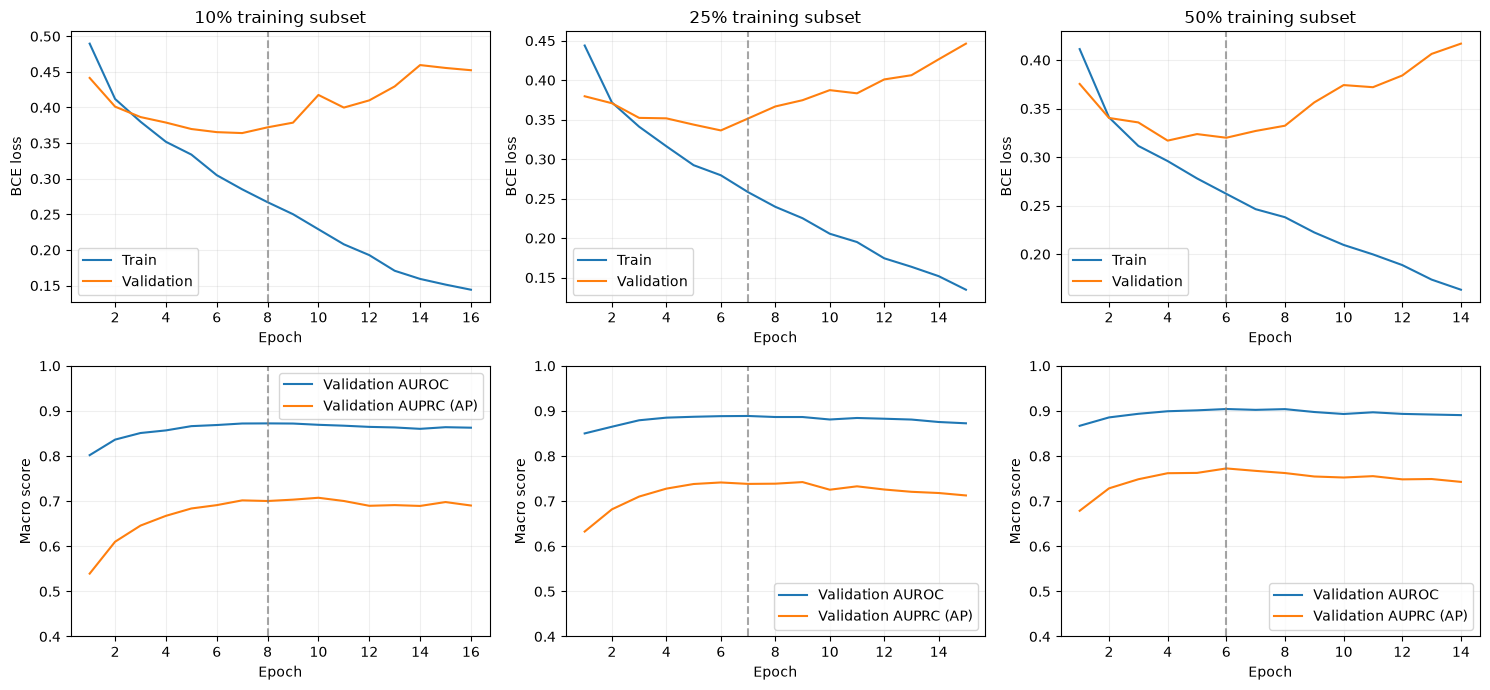

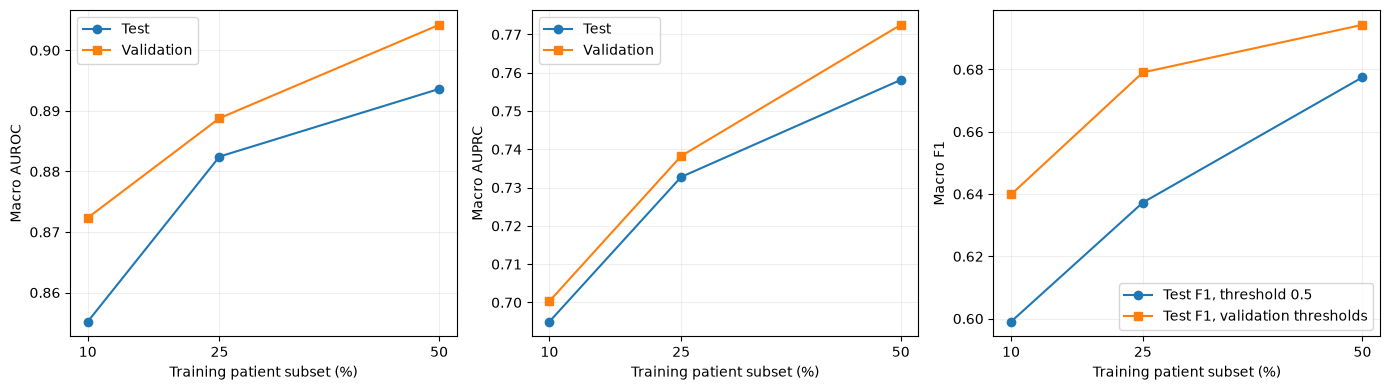

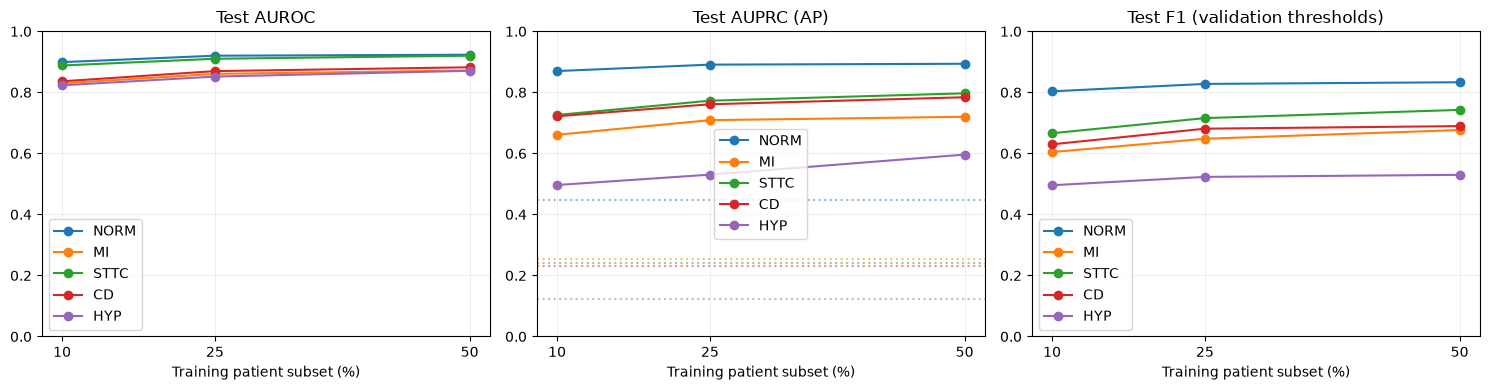

In [10]:
fig, axes = plt.subplots(2, len(TRAIN_PERCENTS), figsize=(5 * len(TRAIN_PERCENTS), 7), squeeze=False)
for j, percent in enumerate(TRAIN_PERCENTS):
    history = pd.read_csv(RUN_DIR / f'train_{percent}' / 'history.csv')
    axes[0, j].plot(history.epoch, history.train_loss, label='Train')
    axes[0, j].plot(history.epoch, history.val_loss, label='Validation')
    axes[0, j].set(title=f'{percent}% training subset', xlabel='Epoch', ylabel='BCE loss')
    axes[0, j].legend()
    axes[1, j].plot(history.epoch, history.val_macro_AUROC, label='Validation AUROC')
    axes[1, j].plot(history.epoch, history.val_macro_AUPRC, label='Validation AUPRC (AP)')
    axes[1, j].set(xlabel='Epoch', ylabel='Macro score', ylim=(0.4, 1))
    axes[1, j].legend()
    for row in range(2):
        axes[row, j].axvline(training_runs[percent]['best_epoch'], color='gray', linestyle='--', alpha=0.7)
        axes[row, j].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_curves.png', dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes[:2], ['AUROC', 'AUPRC']):
    ax.plot(test_summary.index, test_summary[f'macro_{metric}'], marker='o', label='Test')
    ax.plot(training_summary.index, training_summary[f'val_macro_{metric}'], marker='s', label='Validation')
    ax.set(xlabel='Training patient subset (%)', ylabel=f'Macro {metric}', xticks=list(TRAIN_PERCENTS))
    ax.legend()
axes[2].plot(test_summary.index, test_summary['macro_F1_at_0.5'],
             marker='o', label='Test F1, threshold 0.5')
axes[2].plot(test_summary.index, test_summary.macro_F1_val_threshold,
             marker='s', label='Test F1, validation thresholds')
axes[2].set(xlabel='Training patient subset (%)', ylabel='Macro F1', xticks=list(TRAIN_PERCENTS))
axes[2].legend()
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / 'test_learning_curves.png', dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in CLASSES:
    subset = classwise_results.xs(name, level='class')
    for ax, metric in zip(axes, ['AUROC', 'AUPRC', 'F1_val_threshold']):
        line, = ax.plot(subset.index, subset[metric], marker='o', label=name)
        if metric == 'AUPRC':
            ax.axhline(subset.prevalence.iloc[0], color=line.get_color(), linestyle=':', alpha=0.5)
for ax, title in zip(axes, ['Test AUROC', 'Test AUPRC (AP)', 'Test F1 (validation thresholds)']):
    ax.set(title=title, xlabel='Training patient subset (%)', xticks=list(TRAIN_PERCENTS), ylim=(0, 1))
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'classwise_learning_curves.png', dpi=150)
plt.show()

## Compare measurements with the estimates

The following table preserves the original ranges and reports where each
single-seed measurement landed. Falling in a predicted range does not establish
statistical confidence. Threshold selection helps evaluate ranking quality as
binary predictions, but may overfit validation labels. More data need not improve
every metric monotonically for a single seed and a fixed training schedule.

In [11]:
expected = {
    10: {'AUROC': (0.84, 0.89), 'AUPRC': (0.65, 0.75), 'F1': (0.60, 0.70)},
    25: {'AUROC': (0.88, 0.92), 'AUPRC': (0.73, 0.82), 'F1': (0.68, 0.77)},
    50: {'AUROC': (0.90, 0.94), 'AUPRC': (0.77, 0.86), 'F1': (0.72, 0.81)},
}
comparison = []
for percent in TRAIN_PERCENTS:
    for name, column in [('AUROC', 'macro_AUROC'), ('AUPRC', 'macro_AUPRC'), ('F1', 'macro_F1_val_threshold')]:
        low, high = expected[percent][name]
        actual = float(test_summary.loc[percent, column])
        comparison.append({'train_percent': percent, 'metric': name, 'expected_low': low,
                           'expected_high': high, 'measured': actual,
                           'position': 'below' if actual < low else 'above' if actual > high else 'within'})
expectation_comparison = pd.DataFrame(comparison).set_index(['train_percent', 'metric'])
display(expectation_comparison.round(4))
expectation_comparison.to_csv(RUN_DIR / 'expectation_comparison.csv')
print(f'Executed experiment saved to {RUN_DIR}')
print('Classwise results: test_classwise.csv; aggregate results: test_summary.csv')

expected_low  expected_high  measured position
train_percent metric                                                
10            AUROC           0.84           0.89    0.8552   within
              AUPRC           0.65           0.75    0.6950   within
              F1              0.60           0.70    0.6399   within
25            AUROC           0.88           0.92    0.8825   within
              AUPRC           0.73           0.82    0.7328   within
              F1              0.68           0.77    0.6790    below
50            AUROC           0.90           0.94    0.8936    below
              AUPRC           0.77           0.86    0.7581    below
              F1              0.72           0.81    0.6943    below

Executed experiment saved to /home/madrdx/DL/project/ecg_project/artifacts/transformer_v2/20261027T020054956545Z_seed42
Classwise results: test_classwise.csv; aggregate results: test_summary.csv


## Interpretation and reproducibility limits

AUROC measures ranking across positive and negative records; AP emphasizes
precision/recall and depends on prevalence; F1 depends on the chosen threshold.
HYP has fewer positive examples, so its AP/F1 may lag even with useful AUROC.
All results here are from one seed, one architecture, and the existing nested
patient subsets. There are no confidence intervals or CNN ablations. Neither
clinical usefulness nor superiority over ResNet/InceptionTime follows from
these results alone. The fixed 30-epoch schedule may also leave larger subsets
undertrained or allow smaller subsets to overfit; inspect the saved curves.

Run artifacts include input hashes, split counts, normalization statistics,
configuration, epoch histories, model weights, frozen thresholds, validation/test
probabilities with ECG and patient IDs, classwise and macro/micro metrics, and
PNG figures. The `signals.npy` file is a raw cache, not needed for inference if
the original WFDB recordings are available. Normalization is part of each model
checkpoint. Rerunning this notebook starts a new run without overwriting v1 or
previous experiments. Exact floating-point results may vary across hardware and
PyTorch versions; deterministic algorithms are requested with warnings enabled.

## Observed results and interpretation

All 11 code cells completed successfully on CPU. The three independent runs
stopped after 16, 15, and 14 epochs and selected epochs 8, 7, and 6, respectively.
Total epoch-loop training/evaluation time was approximately 14 minutes.

| Training subset | Test macro AUROC | Test macro AUPRC (AP) | Test macro F1 at 0.5 | Test macro F1, validation thresholds |
|---|---:|---:|---:|---:|
| 10% | 0.8552 | 0.6950 | 0.5990 | 0.6399 |
| 25% | 0.8825 | 0.7328 | 0.6373 | 0.6790 |
| 50% | 0.8936 | 0.7581 | 0.6775 | 0.6943 |

Classwise test F1 using the frozen validation thresholds:

| Class | 10% | 25% | 50% |
|---|---:|---:|---:|
| NORM | 0.8034 | 0.8277 | 0.8332 |
| MI | 0.6044 | 0.6479 | 0.6766 |
| STTC | 0.6660 | 0.7156 | 0.7426 |
| CD | 0.6298 | 0.6810 | 0.6894 |
| HYP | 0.4956 | 0.5230 | 0.5298 |

More training patients improved all three macro metrics. My initial 50% estimates
(AUROC 0.90–0.94, AUPRC 0.77–0.86, F1 0.72–0.81) were optimistic for this
configuration: measured scores were 0.8936, 0.7581, and 0.6943. NORM was
strongest and HYP remained the weakest class by AP and F1.

The training curves show increasing validation BCE loss after the early epochs,
despite continuing declines in training loss. This suggests overfitting and does
not support adding more layers or attention heads as the next step. The
128-dimensional, four-head, three-layer CNN–Transformer is a workable baseline;
a fair 1D ResNet/InceptionTime comparison, stronger regularization or ECG
augmentation, and repeated seeds would better establish which model family
and capacity are appropriate. No such follow-up was selected using this test set.

An independent check reproduced all classwise AUROC/AP scores and both F1
policies from all six exported validation/test prediction files. The frozen
split labels were used throughout, including the documented validation MI
discrepancy for ECG 3799.